# Bestrahlungsstärke (Teil 1)

Potenzialanalyse für Dachflächen-Photovoltaik

Photovoltaikanlagen (PV-Anlagen) auf Dachflächen leisten einen
bedeutenden Beitrag zum Klimaschutz, da sie erneuerbare Solarenergie
nutzen, um Strom zu erzeugen. Dadurch wird der Bedarf an fossilen
Brennstoffen wie Kohle, Öl und Gas reduziert, die bei der Verbrennung
CO<sub>2</sub> und andere Treibhausgase freisetzen, welche den
Klimawandel beschleunigen.

Da Dachflächen häufig ungenutzt bleiben, bieten sie eine ideale
Möglichkeit, um umweltfreundliche Energie zu gewinnen, ohne zusätzlichen
Raum zu beanspruchen. Zudem tragen PV-Anlagen zur Dezentralisierung der
Energieversorgung bei, was die Netzstabilität erhöht und Energieverluste
minimiert.

**Wie sieht es in deiner Nachbarschaft aus? Gibt es dort ungenutzte
Dachflächen, die sich für PV-Anlagen eignen?**

<figure>
<img src="figures/pv.png"
alt="Foto „Photovoltaikanlage 2001“ (Ausschnitt) von erhard.renz unter der Lizenz CC BY 2.0 via Flickr" />
<figcaption aria-hidden="true">Foto „Photovoltaikanlage 2001“
(Ausschnitt) von <a
href="https://www.flickr.com/photos/28237570@N08">erhard.renz</a> unter
der Lizenz <a href="https://creativecommons.org/licenses/by/2.0/">CC BY
2.0</a> via <a
href="https://www.flickr.com/photos/28237570@N08/7528987754">Flickr</a></figcaption>
</figure>
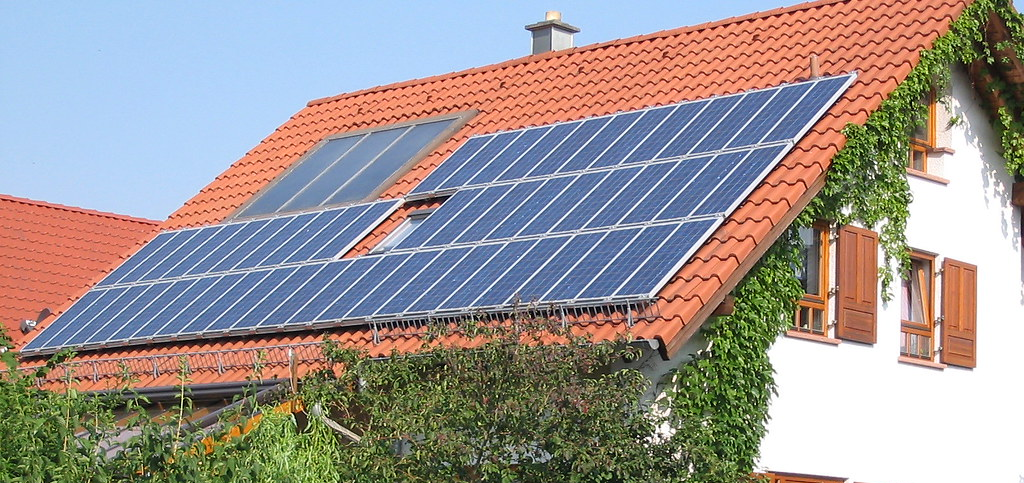

## 1 Daten einlesen

Um die Fragestellung beantworten zu können, wird eine Übersicht über
alle Dachflächen in Ihrer Region benötigt.

Zunächst wird ein Standort festgelegt, für den die Dachflächen
eingelesen werden sollen. Dazu wird eine Variable `adresse` mit der
entsprechenden Adresse definiert. Mit Hilfe der Bibliothek `geopy` wird
daraus anschließend der Breiten- und Längengrad des Standorts bestimmt.

In [ ]:
from geopy import Nominatim

# Adresse eingeben (Gesamtschule Salzkotten)
adresse = 'Upsprunger Straße 65-67, 33154 Salzkotten'

# Geocoder erstellen
geolocator = Nominatim(user_agent='my_user_agent')

# Breiten- und Längengrad bestimmen
ort = geolocator.geocode(adresse)
latitude, longitude = ort.latitude, ort.longitude

print(f'Breitengrad: {latitude}, Längengrad: {longitude}')

> **Hinweis**
>
> Die Adresse muss im Bezirk Detmold liegen.

Mit Hilfe der Funktion `download_roofs()` werden die Dachflächen in der
Umgebung des angegebenen Standorts heruntergeladen. Die Funktion
bereitet die Daten auf und speichert sie als Datei unter dem angegebenen
Pfad `path`.

Die Daten stammen von dem Landesamt für Natur, Umwelt und Klima
Nordrhein-Westfalen (LANUK).

> **Hinweis**
>
> Beim ersten Aufruf müssen die Rohdaten heruntergeladen werden. Das
> kann einige Minuten dauern.

In [ ]:
# Pfad, unter dem die Dachflächen gespeichert werden (Ordner `data`)
path = 'data/dachflaechen.geojson'

In [ ]:
from util import download_roofs

# Dachflächen für die angegebene Adresse herunterladen und als GeoJSON-Datei speichern
download_roofs(
    latitude=latitude,
    longitude=longitude,
    path=path
)

Die Dachflächen liegen nun als Datei `dachflaechen.geojson` im Ordner
`data` vor. GeoJSON ist ein weit verbreitetes Dateiformat für
Vektordaten.

Mit der Funktion `read_file()` aus der Bibliothek `geopandas` kann die
Datei über ihren Pfad eingelesen werden. Als Ergebnis erhält man eine
Tabelle, die neben den üblichen Spalten auch die Form (Geometrie) der
Dachflächen enthält. Die Spalte `id` wird dabei als Index der Tabelle
verwendet.

In [ ]:
from geopandas import read_file

# Datei über den Pfad einlesen (die Spalte `id` wird als Index verwendet)
df = read_file(path).set_index('id')

# Daten anzeigen
df

#### Aufgabe 1

-   Was könnten die Spalten `richtung`, `neigung` und `himmel_kat`
    bedeuten?
-   **Stelle für jede der Spalten eine Vermutung auf!** (1 – 2 Sätze)

(5 Minuten)

**Antwort**

Hier Antwort einfügen:

`richtung`:

`neigung`:

`himmel_kat`:

## 2 Daten explorieren

Mit der Methode `explore()` können die Dachflächen auf einer Karte
dargestellt werden.

> **Hinweis**
>
> Die Form (Geometrie) einer Dachfläche ergibt sich dabei aus der Spalte
> `geometry`. Diese enthält für jede Dachfläche eine Liste mit den
> entsprechenden Eckpunkten.

In [ ]:
df.explore()

Mit Hilfe der Methode `loc` (locate) kann ein einzelner Eintrag aus dem
Datensatz ausgewählt (selektiert) werden. Dazu muss nur die
Identifikationsnummer `id` des entsprechenden Eintrags angeben werden.
Diese kann aus der ersten Spalte des Datensatzes oder aus der
Kartendarstellung abgelesen werden.

``` python
# Selektiere das Dach mit der ID 270
dach = df.loc[270]
dach
```

    geb_id                                         Geb62092ln0403_c
    richtung                                                    148
    neigung                                                      31
    dachtyp                                                 geneigt
    himmel_kat                                                  Süd
    geometry      MULTIPOLYGON (((472325.5 5723153, 472326.5 572...
    Name: 270, dtype: object

Codefragment 1

#### Aufgabe 2

1.  Ändere oben die Variable `adresse` zu einem Ort ihrer Wahl (z.B.
    ihrem Wohnort oder Schule).
2.  Führe anschließend die nachfolgenden Zellen erneut aus.
3.  Wähle auf der Karte eine beliebige Dachfläche aus (z.B. ihr Wohnort
    oder Schule) und notiere die dazugehörige ID `ìd`.
4.  Selektiere die Dachfläche mit Hilfe der Methode `loc` (siehe nächste
    Zelle). Verwende dazu die ID.

*(5 Minuten)*

### 2.1 Neigung und Ausrichtung der Dachfläche

Mit Hilfe der folgenden Schreibweise kann die Neigung und Ausrichtung
der Dachfläche bestimmt werden. Diese beiden Werte werden später noch
wichtig sein, für die Berechnung der Bestrahlungsstärke!

In [ ]:
# Neigungswinkel der Dachfläche
surface_tilt = dach['neigung']
surface_tilt

In [ ]:
# Ausrichtung der Dachfläche (Azimutwinkel, -1 = Flachdach)
surface_azimuth = dach['richtung']
surface_azimuth

### 2.2 Größe der Dachfläche

In gleicher Weise kann auf die Form (`geometry`) der Dachfläche
zugegriffen werden.

In [ ]:
geometry = dach['geometry']
geometry

Mit dem Attribut `.area` kann zudem der Flächeninhalt der Form ermittelt
werden. Die Größe der Dachfläche ist ein weiterer wichtiger Faktor für
die Eignung einer Dachfläche (in Quadratmeter) für die Nutzung von
Photovoltaik.

In [ ]:
# Berechnung des Flächeninhalts in Quadratmetern
surface_area = geometry.area
surface_area

In [ ]:
# Berechnung des Flächeninhalts (qm) aller Dachflächen
df['flaecheninhalt'] = df['geometry'].area
df

## 3 Bestrahlungsstärke

Die Eignung einer Dachfläche für den Einsatz von Photovoltaik hängt
unter anderem von der **Ausrichtung und Neigung der Dachfläche** ab.
Auch der Standort und die zur Verfügung stehende Fläche spielen eine
Rolle.

Je besser die Dachfläche zur Sonne ausgerichtet ist, desto höher ist die
Sonneneinstrahlung und damit die potenziell nutzbare Energie!

Um das Potenzial der Dachflächen für den Einsatz von Photovoltaik zu
ermitteln, wird daher zunächst die **Bestrahlungsstärke** (engl.
irradiance) über einen festgelegten Zeitraum (z.B. ein Jahr) berechnet.
Die Bestrahlungsstärke ist ein **Maß für die Intensität der
Sonneneinstrahlung**, die auf die Dachfläche trifft.

Zur Berechnung der Bestrahlungsstärke sind folgende Schritte
erforderlich:

1.  Genaue Position und Zeitzone bestimmen (Lokalisierung)
2.  Untersuchungszeitraum festlegen
3.  Stand der Sonne berechnen
4.  Trübung der Atmosphäre ermitteln (Bewölkung)
5.  Bestrahlungsstärke berechnen

Glücklicherweise gibt es eine Programmierbibliothek `pvlib`, die einen
Großteil der Berechnungen übernimmt.

In [ ]:
# Bibliothek für den Umgang mit Photovoltaik
import pvlib

### 3.1 Lokalisierung

Zur Lokalisierung wird neben Längen- und Breitengrad auch die
entsprechende Zeitzone benötigt.

In [ ]:
from pytz import timezone

# Zeitzone festlegen
tz = timezone('Europe/Berlin')
tz

Nun kann eine genaue Lokalisierung vorgenommen werden. Diese wird für
die Berechnung des Sonnenstandes und der Bestrahlungsstärke benötigt.

In [ ]:
from pvlib.location import Location

# Lokalisierung
location = Location(
    name=adresse,
    latitude=latitude,
    longitude=longitude,
    tz=tz,
)

location

### 3.2 Zeitraum festlegen

Als letztes muss der Zeitraum festgelegt werden, für den die
Bestrahlungstärke berechnet werden soll.

Die Frequenz wird auf eine Stunde festgelet `1h`, sodass die
Bestrahlungsstärke stundenweise berechnet wird.

In [ ]:
import pandas as pd

# Startzeitpunkt
start = '2024-06-01'

# Endzeitpunkt
end = '2024-06-02'

# Frequenz (stuendlich)
freq = '1h'

# Zeitraum festlegen
date_range = pd.date_range(
    start=start,
    end=end,
    freq=freq,         
    tz=tz,
    inclusive='left'
)

# Zeitpunkte ausgeben
date_range

#### Aufgabe 3

-   Ändere den Startzeitpunkt auf Heute und den Endzeitpunkt auf Morgen
-   Führe anschließend die Zelle erneut aus

*(5 Minuten)*

### 3.3 Stand der Sonne

**Elevation (Höhenwinkel):** Die Elevation gibt den vertikalen Winkel
an, unter dem die Sonne am Himmel steht. Ein Höhenwinkel von 0°
bedeutet, dass die Sonne direkt über einem Punkt am Horizont steht,
während ein Höhenwinkel von 90° darauf hinweist, dass die Sonne im Zenit
steht. Ein negativer Höhenwinkel zeigt an, dass die Sonne unterhalb des
Horizonts ist.

**Azimuth (Azimutwinkel):** Der Azimuthwinkel gibt die horizontale
Richtung der Sonne an, gemessen im Uhrzeigersinn von Norden aus. Ein
Azimut von 0° entspricht dem Norden, 90° dem Osten, 180° dem Süden und
270° dem Westen. Der Azimuthwinkel gibt also an, in welche
Himmelsrichtung die Sonne zu einem bestimmten Zeitpunkt zeigt.

In [ ]:
# Sonnenstand für den gegebenen Standort ermitteln
solar_position = location.get_solarposition(date_range)
solar_position

#### Höhenwinkel

In [ ]:
import plotly.express as px

# Liniendiagramm des Höhenwinkels
fig = px.line(solar_position, y='elevation', title='Höhenwinkel der Sonne im Verlauf eines Tages')

fig.update_xaxes(title="Uhrzeit")
fig.update_yaxes(title="Höhenwinkel")

fig.show()

#### Aufgabe 4

-   Um wie viel Uhr ist die Sonne heute circa aufgegangen?
-   Um wie viel Uhr wird die die Sonne heute circa untergehen?

*(5 Minuten)*

**Antwort**

*Gebe hier deine Antwort ein!*

#### Azimutwinkel

Nun wird der Azimuthwinkel, also die Himmelsrichtung aus welcher die
Sonne scheint, betrachtet.

In [ ]:
px.line(solar_position, y='azimuth')

> **Hinweis**
>
> “Im Osten geht die Sonne auf, im Süden nimmt sie ihren Lauf, im Westen
> wird sie untergehen, im Norden ist sie nie zu sehen.”

### 3.4 Sonneneinstrahlung bei klarem Himmel

Neben der Ausrichtung und Neigung der Dachfläche spielt auch das Wetter
eine Rolle für die Intensität der Sonneneinstrahlung. **Bei starker
Bewölkung ist die Sonneneinstrahlung geringer.**

Im Rahmen der Analyse wird der Einfachheit halber davon ausgegangen,
dass der Himmel klar ist und die Atmosphäre somit nicht durch Wolken
getrübt ist (clear sky).

Mit Hilfe der Methode `get_clearsky()` lässt sich die Sonneneinstrahlung
am gegebenen Standort ermitteln. Es werden drei Arten der
Sonneneinstrahlung unterschieden: GHI, DNI & DHI (siehe unten).

In [ ]:
clear_sky = location.get_clearsky(date_range)
clear_sky

**Direct Normal Irradiance (DNI)**

Die Direktnormalstrahlung (DNI) ist die Menge der Sonnenstrahlung, die
pro Flächeneinheit auf eine **senkrecht zur Sonne stehende Fläche**
auftrifft.

**Global Horizontal Irradiance (GHI)**

Die globale horizontale Einstrahlung (GHI) ist die Gesamtstrahlung, die
von einer **horizontalen Fläche** auf der Erde absorbiert wird.

**Diffuse Horizontal Irradiance (DHI)**

Die diffuse horizontale Einstrahlung (DHI) ist die terrestrische
Einstrahlung, die von einer flachen Oberfläche **gestreut oder diffus
von der Atmosphäre zurückgestrahlt** wird. DHI ist der Teil der globalen
horizontalen Einstrahlung, der nicht von der direkten Sonnenstrahlung
stammt.

In [ ]:
# Sonneneinstrahlung in Liniendiagramm anzeigen
px.line(clear_sky)

### 3.5 Bestrahlungsstärke berechnen

Zunächst wird die Neigung `tilt` und die Ausrichtung `azimuth` der
Dachfläche festgelegt.

In [ ]:
# Neigung
surface_tilt = 20
# Ausrichtung (Süd-Süd-Ost)
surface_azimuth = 160

Nun kann die Bestrahlungsstärke für die Dachfläche mit Hilfe der
Funktion `get_total_irradiance` berechnet werden.

In [ ]:
from pvlib.irradiance import get_total_irradiance

# Bestrahlungsstärke (irradiance) berechnen
irradiance = get_total_irradiance(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    dni=clear_sky['dni'],
    ghi=clear_sky['ghi'],
    dhi=clear_sky['dhi'],
    solar_zenith=solar_position['zenith'],
    solar_azimuth=solar_position['azimuth']
)

# Ausgabe (Watt pro Quadratmeter
irradiance

Alle Angaben sind in $W / m^2$ (Watt pro Quadratmeter).

Für die weitere Analyse ist primär die globale Bestrahlungsstärke
(`poa_global`) von Bedeutung. Diese setzt sich aus der direkten und
indirekten Sonneneinstrahlung zusammen.

$$\mathrm{poa\_global} = \mathrm{poa\_direct} + \mathrm{poa\_diffuse}$$

$$\mathrm{poa\_diffuse} = \mathrm{poa\_sky\_diffuse} + \mathrm{poa\_ground\_diffuse}$$

In [ ]:
# Liniendiagramm (mit eingeschlossener Fläche) der globalen Bestrahlungsstärke
fig = px.area(irradiance, y='poa_global', title="Globale Bestrahlungsstärke im Verlauf eines Tages")

fig.update_xaxes(title="Uhrzeit")
fig.update_yaxes(title="Globale Bestrahlungsstärke<br>[W/m<sup>2</sup>]")

fig.show()

#### Tagesleistung

> **Hinweis**
>
> Zur Erinnerung: Die **Bestrahlungsstärke** gibt nur die Intensität der
> Sonneneinstrahlung an und ist **nicht** von der Größe der Dachfläche
> abhängig. Sie wird daher in der Einheit $W/m^2$ angegeben.

Die Summe der Stundenwerte ergibt die **Bestrahlungsenergie pro
Quadratmeter** ($Wh / m^2$) `energy_per_area` an dem entsprechenden Tag.

In [ ]:
# Summe der Stundenwerte (in Wattstunden pro Quadratmeter)
energy_per_area = irradiance['poa_global'].sum()
energy_per_area

Um die **Strahlungsenergie** zu bestimmen, die im Laufe eines Tages auf
die Dachfläche auftrifft, muss das Ergbnis nun nur noch mit der Größe
der Dachfläche multipliziert werden.

In [ ]:
# Größe der Dachfläche in Quadratmeter (Beispiel)
surface_area = 10

# Berechnung der Strahlungsenergie (Wattstunden)
total_energy = energy_per_area * surface_area

# Ausgabe (auf zwei Nachkommastellen gerundet)
print('Tagesleistung:', total_energy.round(2), 'Wh')

Die Strahlungsenergie hat die Einheit $Wh$ (Wattstunden).

**Beispiel:** Mit 1600 Wh kann eine Mikrowelle mit einem Stromverbrauch
von 800 Watt 2 Stunden betrieben werden.

Um die Energie in Kilowattstunden anzugeben, muss der Wert einfach durch
1000 geteilt werden.

In [ ]:
# W in kW umrechnen
total_energy = total_energy / 1000

# Ausgabe
print('Tagesleistung:', total_energy.round(2), 'kW')

> **Hinweis**
>
> Hierbei handelt es sich um die potenziell nutzbare Sonnenenergie, die
> auf die PV-Anlage trifft. Nur ein Teil davon kann tatsächlich in Strom
> umgewandelt werden. Zudem kann in der Regel aufgrund der Dachform
> nicht die gesamte Fläche mit PV-Anlagen versehen werden.

#### Aufgabe 5

-   Bestimme die optimale Ausrichtung und Neigung einer Dachfläche für
    den Einsatz von PV unter den oben definierten Bedigungen.
-   Verändere dazu die Schieberegler für die Parameter `surface_tilt`
    und `surface_area`.
-   Ziel ist es, den Wert für die Bestrahlungsenergie zu maximieren.

(5 Minuten)

> **Hinweis**
>
> Um mit der folgenden Abbildung interagieren zu können, muss das
> Notebook in einer Jupyter Umgebung ausgeführt werden!

In [ ]:
from util import interactive_irradiance

interactive_irradiance(clear_sky, solar_position)

**Antwort**

*Klicke hier, um deine Antwort einzugeben.*

#### Jahresleistung

Nun soll die Bestrahlungsstärke **über einen Zeitraum von einem Jahr**
hinweg betrachtet werden.

#### Aufgabe 6

-   Kopiere den folgeden Programmcode in die dafür vorgesehene Zelle.
-   Vervollständige den Programmcode so, dass die Bestrahlungsstärke im
    Laufe eines Jahres berechnet wird:
    -   Ändere den Wert der Variablen `surface_tilt` und
        `surface_azimuth` entsprechend den Werten für das von Ihnen
        ausgewählten Daches (siehe
        <a href="#lst-roof-select" class="quarto-xref">Code 1</a>).
    -   Ändere den Start- und Endzeitpunkt so, dass die Zeitspanne genau
        **ein Jahr** beträgt.

*(15 Minuten)*

| Größe | Einheit | Variable | Berechnung |
|------------------|------------------|------------------|------------------|
| Bestrahlungsstärke | Watt pro Quadratmeter \[$W / m^2$\] | `irradiance` |  |
| Bestrahlungsenergie pro Quadratmeter | Wattstunden pro Quadratmeter \[$Wh / m^2$\] | `total_irradiance` | `irradiance.sum()` |
| Bestrahlungsenergie | Wattstunden \[$Wh$\] | `total_energy` | `total_irradiance * surface_area` |

``` python
# Neigung der Dachfläche eingeben
surface_tilt =
# Ausrichtung der Dachfläche eingeben
surface_azimuth =

# Funktion zu Berechnung der Bestrahlungsstärke über ein Jahr
def get_annual_irradiance(surface_tilt, surface_azimuth):
    
    # Startzeitpunkt eingeben
    start = 
    # Endzeitpunkt eingeben
    end = 
                        
    # Zeitraum festlegen
    date_range = pd.date_range(
        start=start,
        end=end,
        freq='1h',
        tz=tz,
        inclusive='left'
    )
    
    # Stand der Sonne bestimmen
    solar_position = location.get_solarposition(date_range)
    
    # Klarer Himmel
    clear_sky = location.get_clearsky(date_range)
    
    # Bestrahlungsstärke berechnen
    irradiance = get_total_irradiance(
        surface_tilt=surface_tilt,
        surface_azimuth=surface_azimuth,
        dni=clear_sky['dni'],
        ghi=clear_sky['ghi'],
        dhi=clear_sky['dhi'],
        solar_zenith=solar_position['zenith'],
        solar_azimuth=solar_position['azimuth']
    )

    irradiance = irradiance['poa_global']

    return irradiance

irradiance = get_annual_irradiance(surface_tilt, surface_azimuth)

irradiance
```

In [ ]:
# Hier Code einfügen

## 4 Jahresverlauf

Nun kann die Veränderung der Bestrahlungsstärke im Verlauf eines Jahres
betrachtet werden.

In [ ]:
# Tagesleistung im Verlauf des Jahres bestimmen
daily = irradiance.resample('1D').sum()

# Liniendiagramm des Jahresverlauf
fig = px.line(daily, title="Bestrahlungsstärke im Verlauf eines Jahres")

fig.update_xaxes(title="Zeitpunkt")
fig.update_yaxes(title="Bestrahlungsstärke<br>[W/m<sup>2</sup>]")

fig.show()

## 5 Dachlächenpotenzial berechnen

Mit Hilfe der zuvor erstellten Funktion kann nun die Bestrahlungsenergie
**aller Dachflächen** über den Zeitraum eines Jahres bestimmt werden.

In [ ]:
# Fortschrittsbalken
from tqdm.auto import tqdm
tqdm.pandas()

# Funktion zur Berechnung der Bestrahlungsenergie pro Quadratmeter pro Jahr für ein Dach
def calculate_total_energy_per_square_metre(dach):
    # Ermittel Neigung und Ausrichtung der Dachfläche
    surface_tilt = dach['neigung']
    surface_azimuth = dach['richtung']

    # Jährliche Bestrahlungsstärke
    irradiance = calculate_irradiance_over_one_year(surface_tilt, surface_azimuth)

    total_energy_per_square_metre = irradiance.sum()

    # Rückgabe der Strahlungsenergie pro Quadratmeter
    return total_energy_per_square_metre

# Wende die Funktion auf alle Dächer aus den Datensatz an
total_energy_per_square_metre = df.progress_apply(calculate_total_energy_per_square_metre, axis=1)

# Füge das Resultat in die Spalte irradiance ein
df['total_energy_per_square_metre'] = total_energy_per_square_metre

# Berechne die Bestrahlungsenergie
df['total_energy'] = df['total_energy_per_square_metre'] * df['flaecheninhalt']

df

Nun kann die Dachflächen wieder auf einer Karte angezeigt werden. Die
Einfärbung der Dachflächen ergibt sich nun aus dem Wert der
Strahlungsenergie pro Quadratmeter.

In [ ]:
df.explore(column='total_energy_per_square_metre', style_kwds=dict(weight=0))

## 6 Eignung bestimmen

Eine **geneigte Dachfläche** ist dann für den Einsatz von PV geeignet
wenn

-   die Strahlungsenergie pro Quadratmeter pro Jahr mindestens 1500 kW
    beträgt und
-   die Dachfläche mindestens 20 Quadratmeter groß ist.

Bei **Flachdächern** wird angenommen, dass bei einer Aufständerung nach
Süden **40 Prozent der Fläche** genutzt werden kann. Flachdächer müssen
daher mindestens eine Größe von **50 Quadratmeter** aufweisen, um als
geeignet eingestuft zu werden.

#### Aufgabe 7

-   Filtere die Daten ensprechend der oben genannten Kriterien.
-   Berücksichtige dabei auch die Flachdächer!
-   Der Datensatz `df` soll anschließend nurnoch die geeigneten
    Dachflächen enthalten.

(15 Minuten)

> **Tip**
>
> Wie im ersten Arbeitsblatt (Luftqualität) können die Daten mit
> folgender Notation gefiltert werden:
>
> ``` python
> cond = df['Spaltenname'] >= Wert
> df = df[cond]
> ```

In [ ]:
# Hier Code einfügen

## 7 Zwischenstand speichern

An dieser Stelle wird das Zwischenergebnis gespeichert, um dieses im
nächsten Arbeitsblatt (Object Detection) wiederverwenden zu können.

In [ ]:
df.to_file('data/solarkataster.json')

## 8 Zusammenfassung – Bestrahlungsstärke

In diesem Notebook hast du gelernt, wie du:

-   die Potenziale von Dachflächen für Photovoltaik (PV) anhand der
    erwarteten Sonneneinstrahlung analysierst,
-   die Bedeutung von Neigung und Ausrichtung einer Dachfläche für die
    Berechnung der Bestrahlungsstärke verstehst,
-   mit geeigneten Tools (z. B. `pvlib`) die Globalstrahlung berechnest,
-   die gewonnenen Ergebnisse visualisierst, um potenzielle Flächen zu
    identifizieren,
-   die Rolle von PV-Anlagen für Klimaschutz und Energieversorgung
    einordnest,
-   Fragen für die praktische Anwendung reflektierst, z. B. „Welche
    Dächer in der Nachbarschaft wären geeignet?“.